# 08 · The Main Model: Conv1D + Attention

**The question:** Does a Conv1D + attention network, adapted from the reference paper, beat our two reference points?

| Reference point | Macro F1 on `model_selection` |
|---|---|
| Plain neural network, MLP (Notebook 07) | 0.524 |
| LightGBM, the best model so far (Notebook 06) | 0.632 |

| | |
|---|---|
| **Input** | The scaled `total_and_byte44` inputs from Notebook 05 (`train` and `model_selection` roles) |
| **What we do** | Build the network in PyTorch, train it, and run four matched experiments ("arms") to see which parts help |
| **Output** | Trained networks, their predictions and scores, attention plots and a clear answer |

### An honest starting point

The reference paper (Mohan et al.) feeds its model **two measured streams**: network-flow features and **DNS-query** features, grouped into
**5-second time windows**. Our data has no DNS-query records, no timestamps and no IP addresses (Notebook 01).
So this notebook builds a **tabular adaptation**: the same building blocks (two Conv1D branches, fusion, multi-head attention, BiLSTM),
applied to **one row per flow**. It is not a reproduction of the paper's DNS or time-window results.

**Project path:** 01 Data → 02 Fair splits → 03 Preprocessing → 04 Feature engineering → 05 Feature selection → 06 Baselines → 07 MLP → **08 Main model**

## 1. Setup

`RETRAIN = False` means: if a trained network is already saved, load it instead of training again. The first run trains everything
(about 2 hours on this CPU); later runs take a few minutes. Set it to `True` to retrain from scratch.

In [1]:
import sys
import time
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy import sparse
from IPython.display import display
from sklearn.metrics import accuracy_score, average_precision_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold

from src.notebook_helpers import (ROOT, TRAIN_CSV, RAW_SHA256, CLASSES, DATA, MODELS,
                                  sha256, save_table, save_figure, save_json, read_json, setup_style,
                                  write_leaderboard, read_leaderboard)
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

RETRAIN = False
torch.set_num_threads(8)
warnings.filterwarnings('ignore', message='X does not have valid feature names')   # harmless LightGBM naming notice
NORMAL, WORMS = CLASSES.index('Normal'), CLASSES.index('Worms')
CHECKPOINTS = MODELS / '08_checkpoints'
CHECKPOINTS.mkdir(exist_ok=True)
print('PyTorch', torch.__version__, '| threads', torch.get_num_threads())

PyTorch 2.14.0+cu130 | threads 8


## 2. Load the inputs

We use the same scaled inputs as the MLP in Notebook 07 (log + robust scaling, fitted on `train` rows only), so the comparison is fair.

In [2]:
columns = read_json(MODELS / '05_feature_sets.json')['columns']['total_and_byte44/scaled']
matrix = {r: sparse.load_npz(DATA / f'05_total_and_byte44_scaled_{r}.npz').tocsc() for r in ['train', 'model_selection']}
targets = {r: pd.read_csv(DATA / f'03_targets_{r}.csv') for r in ['train', 'model_selection']}
y = {r: pd.Categorical(targets[r].attack_cat, categories=CLASSES).codes.astype(np.int64) for r in targets}
print({r: m.shape for r, m in matrix.items()})

{'train': (140273, 195), 'model_selection': (17534, 195)}


## 3. Turning one flow into a "sequence"

Conv1D slides a small window along a **sequence**. In the paper the sequence is a stream of measurements. Here we make one from the
41 number features of a flow, **ordered by topic** (the groups from Notebook 01), and split into two branches like the paper's two streams:

| Branch | Features | Plays the role of |
|---|---|---|
| **A: flow measurements** | duration, size, speed, timing, header values + the 2 engineered features (28 values) | the paper's network-flow branch |
| **B: content and context** | HTTP/FTP fields and the "recent flows" counters (13 values) | the paper's second branch. **This is not DNS data** |

The three text columns (`proto`, `service`, `state`) do not belong in a sequence of numbers. Each one becomes a small learned **embedding**
(8 numbers per category), which is more compact than the 154 one-hot columns.

In [3]:
BRANCH_A = ['dur',                                                   # basic
            'sbytes', 'dbytes', 'spkts', 'dpkts', 'smean', 'dmean',  # size
            'fe_total_bytes', 'fe_byte_balance',                     # engineered size / direction
            'rate', 'sload', 'dload', 'sloss', 'dloss',              # speed and load
            'sinpkt', 'dinpkt', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdat',   # timing
            'sttl', 'dttl', 'swin', 'dwin', 'stcpb', 'dtcpb', 'is_sm_ips_ports']  # header values
BRANCH_B = ['trans_depth', 'response_body_len', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd',   # content
            'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm',
            'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_state_ttl']                                  # recent-flow counters
TEXT = ['proto', 'service', 'state']


def column_of(feature):
    for prefix in ('log__', 'plain__', ''):
        if prefix + feature in columns:
            return columns.index(prefix + feature)
    raise KeyError(feature)


number_index = [column_of(f) for f in BRANCH_A + BRANCH_B]
assert len(set(number_index)) == 41 and len(BRANCH_A) == 28 and len(BRANCH_B) == 13

# For each text column: which one-hot columns belong to it. Index 0 is kept for "never seen in train".
text_blocks = {t: [i for i, c in enumerate(columns) if c.startswith(f'cat__{t}_')] for t in TEXT}
vocab_size = {t: len(b) + 1 for t, b in text_blocks.items()}
print('categories per text column (+1 for unseen):', vocab_size)


def to_tensors(role):
    m = matrix[role]
    numbers = m[:, number_index].toarray().astype(np.float32)
    codes = []
    for t in TEXT:
        block = m[:, text_blocks[t]].toarray()
        codes.append(np.where(block.max(axis=1) > 0, block.argmax(axis=1) + 1, 0))
    return torch.from_numpy(numbers), torch.from_numpy(np.stack(codes, axis=1).astype(np.int64)), torch.from_numpy(y[role])


data = {r: to_tensors(r) for r in ['train', 'model_selection']}
print('numbers:', tuple(data['train'][0].shape), '| text codes:', tuple(data['train'][1].shape))

categories per text column (+1 for unseen): {'proto': 133, 'service': 14, 'state': 10}


numbers: (140273, 41) | text codes: (140273, 3)


### One real flow, before and after

This is what the network actually receives for the first `train` row (a Normal flow):

In [4]:
first = pd.DataFrame({'feature': BRANCH_A + BRANCH_B, 'branch': ['A'] * 28 + ['B'] * 13,
                      'scaled value': data['train'][0][0].numpy()})
display(first.T)
print('text codes (proto, service, state):', data['train'][1][0].tolist())

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40
feature,dur,sbytes,dbytes,spkts,dpkts,smean,dmean,fe_total_bytes,fe_byte_balance,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,tcprtt,synack,ackdat,sttl,dttl,swin,dwin,stcpb,dtcpb,is_sm_ips_ports,trans_depth,response_body_len,ct_flw_http_mthd,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,ct_state_ttl
branch,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,A,B,B,B,B,B,B,B,B,B,B,B,B,B
scaled value,0.9755,0.2044,0.7895,1.0976,1.0697,-0.4884,11.9326,1.1968,-1.8511,-0.0248,-0.5253,17.2901,0.7925,2.6309,0.9163,0.7062,0.5278,1.5215,0.0000,0.0000,0.0000,-1.0000,0.8849,1.0000,1.0000,0.7422,1.6101,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,3.8000,0.2000,-0.1667,-0.2857,0.0000,0.0000,-0.1000,0.0000


text codes (proto, service, state): [113, 1, 3]


## 4. The network

| Part | What it does | Shape for one flow |
|---|---|---|
| **Conv1D branch A** | 2 layers, window of 3 neighbouring features, 32 then 64 filters | 28 positions × 64 |
| **Conv1D branch B** | the same, for branch B | 13 positions × 64 |
| **Fusion** | join both branches into one sequence and add a learned "position" vector | 41 × 64 |
| **Multi-head attention** | 4 heads; every position looks at every other position and mixes in what is relevant | 41 × 64 |
| **BiLSTM** (arm D only) | reads the sequence forwards and backwards | 41 × 64 |
| **Pooling** | average over the 41 positions | 64 |
| **Text embeddings** | proto, service, state → 8 numbers each, joined on | 64 + 24 = 88 |
| **Head** | dense layer of 128, ReLU, dropout 0.2, then 10 class scores | 10 |

Attention and BiLSTM here work across **feature positions, not time**. They can learn how features relate to each other, but they cannot
learn anything about a sequence of events, because a single row contains none.

In [5]:
class ConvAttentionNet(nn.Module):
    def __init__(self, len_a=28, len_b=13, use_attention=True, use_bilstm=False, channels=64, heads=4):
        super().__init__()
        self.len_a = len_a

        def conv_branch():
            return nn.Sequential(nn.Conv1d(1, 32, kernel_size=3, padding=1), nn.ReLU(),
                                 nn.Conv1d(32, channels, kernel_size=3, padding=1), nn.ReLU())

        self.branch_a, self.branch_b = conv_branch(), conv_branch()
        self.position = nn.Parameter(torch.zeros(1, len_a + len_b, channels))
        self.attention = nn.MultiheadAttention(channels, heads, batch_first=True) if use_attention else None
        self.norm = nn.LayerNorm(channels)
        self.bilstm = nn.LSTM(channels, channels // 2, batch_first=True, bidirectional=True) if use_bilstm else None
        self.embeddings = nn.ModuleList([nn.Embedding(vocab_size[t], 8) for t in TEXT])
        self.head = nn.Sequential(nn.Linear(channels + 8 * len(TEXT), 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 10))

    def forward(self, numbers, codes, return_attention=False):
        a = self.branch_a(numbers[:, None, :self.len_a])           # (batch, 64, 28)
        b = self.branch_b(numbers[:, None, self.len_a:])           # (batch, 64, 13)
        h = torch.cat([a, b], dim=2).transpose(1, 2) + self.position   # fusion: (batch, 41, 64)
        weights = None
        if self.attention is not None:
            mixed, weights = self.attention(h, h, h, need_weights=return_attention)
            h = self.norm(h + mixed)                                # residual connection
        if self.bilstm is not None:
            h, _ = self.bilstm(h)
        pooled = h.mean(dim=1)
        text = torch.cat([emb(codes[:, i]) for i, emb in enumerate(self.embeddings)], dim=1)
        scores = self.head(torch.cat([pooled, text], dim=1))
        return (scores, weights) if return_attention else scores


demo = ConvAttentionNet()
print(demo(data['train'][0][:2], data['train'][1][:2]).shape, '-> 2 flows, 10 class scores each')
print(f'trainable parameters: {sum(p.numel() for p in demo.parameters()):,}')

torch.Size([2, 10]) -> 2 flows, 10 class scores each
trainable parameters: 46,002


## 5. The four experiments ("arms")

Every arm uses the **same data, training rules and budget**. Only one thing changes at a time, so we can see what each part contributes.

| Arm | Network | Question it answers | Seeds |
|---|---|---|---|
| **A. Full model** | Conv1D + attention | the main result | 42, 43, 44 |
| **B. No attention** | Conv1D only | does attention help? (compared with A) | 42, 43, 44 |
| **C. Shuffled order** | Conv1D + attention, features shuffled inside each branch (2 fixed shuffles) | does Conv1D really use the topic order? | 42 |
| **D. + BiLSTM** | Conv1D + attention + BiLSTM, as in the paper | does the paper's last block help on flow rows? | 42 |

Arms A and B get three seeds because they are the main comparison. C and D are single-seed checks.
These choices are fixed **before** training.

In [6]:
rng = np.random.default_rng(2026)
SHUFFLES = {k: np.concatenate([rng.permutation(28), 28 + rng.permutation(13)]) for k in (1, 2)}
ARMS = {
    'A_full':      dict(use_attention=True,  use_bilstm=False, order=None,        seeds=[42, 43, 44]),
    'B_no_attention': dict(use_attention=False, use_bilstm=False, order=None,     seeds=[42, 43, 44]),
    'C_shuffle1':  dict(use_attention=True,  use_bilstm=False, order=SHUFFLES[1], seeds=[42]),
    'C_shuffle2':  dict(use_attention=True,  use_bilstm=False, order=SHUFFLES[2], seeds=[42]),
    'D_bilstm':    dict(use_attention=True,  use_bilstm=True,  order=None,        seeds=[42]),
}
names = np.array(BRANCH_A + BRANCH_B)
print('Shuffle 1, branch A starts with:', names[SHUFFLES[1][:6]].tolist())

Shuffle 1, branch A starts with: ['tcprtt', 'swin', 'sloss', 'sttl', 'rate', 'dload']


## 6. Training rules

- Adam, learning rate 0.001, batch size 512, dropout 0.2 (the paper's settings).
- **At most 100 epochs.** The paper trains for 50, but a fixed limit can cut a slower arm short and make it look worse than it is.
  With 100 we let **early stopping**, not the budget, decide when each arm is finished, so the arms are compared fairly.
- Plain (unweighted) cross-entropy, the same as all earlier models.
- **Early stopping:** we set aside 10% of the `train` rows as a **stopping set**, again keeping identical patterns together (as in Notebook 02).
  After every epoch we measure the loss on it. If it has not improved for 5 epochs we stop and keep the best epoch's weights.
  The `model_selection` rows are **never** used during training.
- The network therefore learns from 90% of the `train` rows (about 126,000), slightly fewer than LightGBM and the MLP. That is a small handicap and we accept it.

In [7]:
roles = pd.read_csv(DATA / '02_roles.csv')
train_patterns = roles.loc[roles.role == 'train', 'pattern'].to_numpy()
assert len(train_patterns) == len(y['train'])
splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
learn_rows, stop_rows = next(splitter.split(np.zeros(len(train_patterns)), y['train'], train_patterns))
assert not set(train_patterns[learn_rows]) & set(train_patterns[stop_rows])
print(f'learning rows: {len(learn_rows):,} | stopping rows: {len(stop_rows):,} | shared patterns: 0')
display(pd.DataFrame({'learning': np.bincount(y['train'][learn_rows], minlength=10),
                      'stopping': np.bincount(y['train'][stop_rows], minlength=10)}, index=CLASSES).T)

learning rows: 126,246 | stopping rows: 14,027 | shared patterns: 0


,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
learning,1440,1257,8830,24043,13093,28800,40320,7553,816,94
stopping,160,140,981,2671,1454,3200,4480,840,91,10


In [8]:
def predict_proba(model, numbers, codes, batch=4096):
    model.eval()
    with torch.no_grad():
        return torch.cat([torch.softmax(model(numbers[i:i + batch], codes[i:i + batch]), dim=1)
                          for i in range(0, len(numbers), batch)]).numpy()


def train_arm(arm, seed, max_epochs=100, patience=5, batch_size=512):
    """Train one network, or load it if it was already trained under the same rules and RETRAIN is False."""
    settings = ARMS[arm]
    path = CHECKPOINTS / f'08_{arm}_seed{seed}.pt'
    order = settings['order'] if settings['order'] is not None else np.arange(41)
    numbers, codes, labels = data['train'][0][:, order], data['train'][1], data['train'][2]

    torch.manual_seed(seed); np.random.seed(seed)
    model = ConvAttentionNet(use_attention=settings['use_attention'], use_bilstm=settings['use_bilstm'])
    if path.exists() and not RETRAIN:
        saved = torch.load(path, weights_only=False)
        old_max, old_patience = saved.get('max_epochs', 50), saved.get('patience', 5)
        stopped_early = len(saved['history']) < old_max
        # A run that stopped early would be exactly the same under a higher epoch limit, so it can be reused.
        if old_patience == patience and (old_max == max_epochs or stopped_early):
            model.load_state_dict(saved['weights'])
            return model, saved['history']
        print(f'{arm} seed {seed}: saved run hit the old {old_max}-epoch limit, retraining under the {max_epochs}-epoch rule')

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.CrossEntropyLoss()
    learn_x, learn_c, learn_y = numbers[learn_rows], codes[learn_rows], labels[learn_rows]
    stop_x, stop_c, stop_y = numbers[stop_rows], codes[stop_rows], labels[stop_rows]
    generator = torch.Generator().manual_seed(seed)
    history, best_loss, best_weights, waited = [], np.inf, None, 0
    for epoch in range(1, max_epochs + 1):
        start = time.time()
        model.train()
        shuffled = torch.randperm(len(learn_y), generator=generator)
        total = 0.0
        for i in range(0, len(shuffled), batch_size):
            rows = shuffled[i:i + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(learn_x[rows], learn_c[rows]), learn_y[rows])
            loss.backward()
            optimizer.step()
            total += loss.item() * len(rows)
        stop_proba = predict_proba(model, stop_x, stop_c)
        stop_loss = float(-np.log(np.clip(stop_proba[np.arange(len(stop_y)), stop_y.numpy()], 1e-12, None)).mean())
        stop_f1 = f1_score(stop_y.numpy(), stop_proba.argmax(1), average='macro', labels=range(10), zero_division=0)
        history.append({'epoch': epoch, 'train loss': total / len(learn_y), 'stopping loss': stop_loss,
                        'stopping macro F1': stop_f1, 'seconds': time.time() - start})
        if stop_loss < best_loss - 1e-4:
            best_loss, waited = stop_loss, 0
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_weights)
    history = pd.DataFrame(history)
    torch.save({'weights': best_weights, 'history': history, 'arm': arm, 'seed': seed,
                'max_epochs': max_epochs, 'patience': patience}, path)
    print(f'{arm} seed {seed}: stopped after {len(history)} epochs, best epoch {int(history["stopping loss"].idxmin()) + 1}, '
          f'{history.seconds.sum() / 60:.1f} min')
    return model, history


networks, histories, probabilities = {}, {}, {}


def run(arm):
    for seed in ARMS[arm]['seeds']:
        model, history = train_arm(arm, seed)
        order = ARMS[arm]['order'] if ARMS[arm]['order'] is not None else np.arange(41)
        networks[(arm, seed)], histories[(arm, seed)] = model, history
        probabilities[(arm, seed)] = predict_proba(model, data['model_selection'][0][:, order], data['model_selection'][1])
        f1 = f1_score(y['model_selection'], probabilities[(arm, seed)].argmax(1), average='macro', labels=range(10))
        print(f'{arm:15s} seed {seed}: model_selection macro F1 = {f1:.4f}')

## 7. Train arm A: the full model

In [9]:
run('A_full')

A_full          seed 42: model_selection macro F1 = 0.5410


A_full          seed 43: model_selection macro F1 = 0.5426


A_full          seed 44: model_selection macro F1 = 0.5210


## 8. Train arm B: without attention

In [10]:
run('B_no_attention')

B_no_attention  seed 42: model_selection macro F1 = 0.5145


B_no_attention  seed 43: model_selection macro F1 = 0.5208


B_no_attention  seed 44: model_selection macro F1 = 0.5083


## 9. Train arms C and D: shuffled order and BiLSTM

In [11]:
run('C_shuffle1')
run('C_shuffle2')
run('D_bilstm')

C_shuffle1      seed 42: model_selection macro F1 = 0.5170


C_shuffle2      seed 42: model_selection macro F1 = 0.5383


D_bilstm        seed 42: model_selection macro F1 = 0.5385


## 10. Did training behave well?

Left: the loss on the learning rows keeps falling. Right: the loss on the separate stopping rows. Where the right-hand curve turns upward,
the network starts to memorise the learning rows; early stopping keeps the best point (marked with a dot).

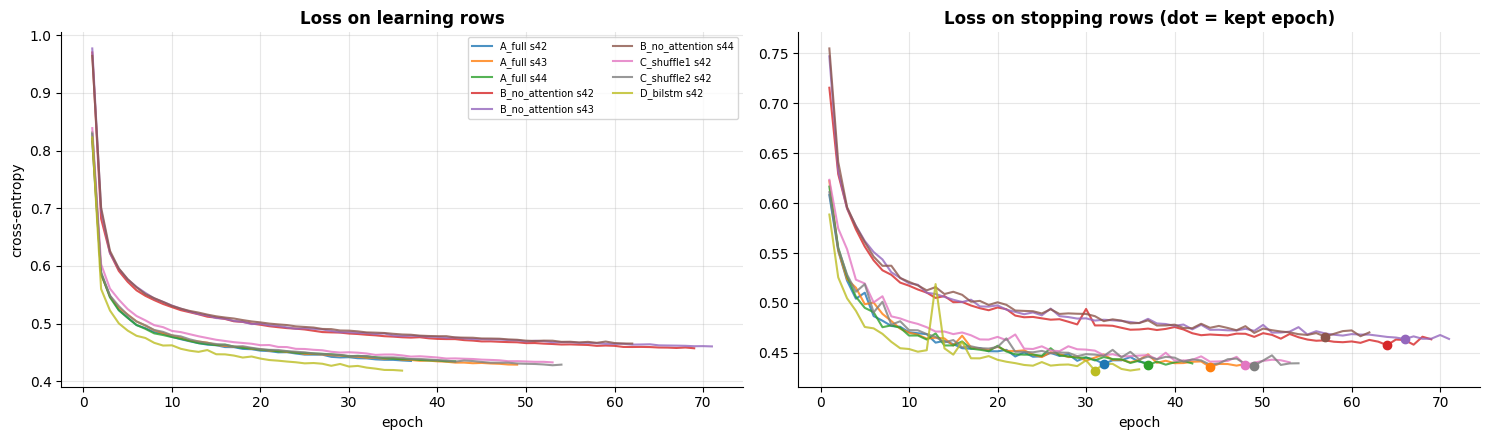

,arm,seed,epochs run,kept epoch,stopped by early stopping,minutes
0,A_full,42,37,32,True,12.0069
1,A_full,43,49,44,True,36.8548
2,A_full,44,42,37,True,31.0852
3,B_no_attention,42,69,64,True,37.9053
4,B_no_attention,43,71,66,True,38.2386
5,B_no_attention,44,62,57,True,36.3076
6,C_shuffle1,42,53,48,True,43.6898
7,C_shuffle2,42,54,49,True,44.0304
8,D_bilstm,42,36,31,True,11.9575


Every run was stopped by early stopping, not by the epoch limit: True


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for (arm, seed), h in histories.items():
    line, = axes[0].plot(h.epoch, h['train loss'], label=f'{arm} s{seed}', alpha=0.8)
    axes[1].plot(h.epoch, h['stopping loss'], color=line.get_color(), alpha=0.8)
    best = h['stopping loss'].idxmin()
    axes[1].scatter(h.epoch[best], h['stopping loss'][best], color=line.get_color(), zorder=3)
axes[0].set(title='Loss on learning rows', xlabel='epoch', ylabel='cross-entropy')
axes[1].set(title='Loss on stopping rows (dot = kept epoch)', xlabel='epoch')
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); save_figure(fig, '08_training_curves'); plt.show()

epochs = pd.DataFrame([{'arm': a, 'seed': s, 'epochs run': len(h), 'kept epoch': int(h['stopping loss'].idxmin()) + 1,
                        'stopped by early stopping': len(h) < 100, 'minutes': h.seconds.sum() / 60} for (a, s), h in histories.items()])
save_table(epochs, '08_epochs')
display(epochs)
print('Every run was stopped by early stopping, not by the epoch limit:', bool(epochs['stopped by early stopping'].all()))

**What we see:**

- **Every run was stopped by early stopping**, none by the 100-epoch limit, so every arm had the chance to finish learning.
- The arms need different amounts of training: with attention (A, D) about 36-49 epochs, without attention (B) about 62-71,
  and with shuffled order (C) about 53-54. Attention lets the network learn faster.
- The loss on the learning rows keeps falling for every run, while the stopping loss flattens: the point where more training stops helping.

## 11. Scores for every run

The same scoring as Notebooks 06 and 07.

In [13]:
def score(y_true, proba):
    pred = proba.argmax(axis=1)
    attack_true, attack_pred = y_true != NORMAL, pred != NORMAL
    fp = int((~attack_true & attack_pred).sum()); tn = int((~attack_true & ~attack_pred).sum())
    tp = int((attack_true & attack_pred).sum()); fn = int((attack_true & ~attack_pred).sum())
    return {'macro F1': f1_score(y_true, pred, average='macro', labels=range(10), zero_division=0),
            'accuracy': accuracy_score(y_true, pred),
            'attack recall': tp / (tp + fn), 'false-positive rate': fp / (fp + tn),
            'attack avg precision': average_precision_score(attack_true, 1 - proba[:, NORMAL]),
            'Worms correct (of 13)': int(((y_true == WORMS) & (pred == WORMS)).sum())}


y_eval = y['model_selection']
runs = pd.DataFrame([{'arm': a, 'seed': s, **score(y_eval, p)} for (a, s), p in probabilities.items()])
save_table(runs, '08_runs')
display(runs)

,arm,seed,macro F1,accuracy,attack recall,false-positive rate,attack avg precision,Worms correct (of 13)
0,A_full,42,0.5410,0.8196,0.9672,0.0945,0.9959,1
1,A_full,43,0.5426,0.8228,0.9729,0.1032,0.9960,1
2,A_full,44,0.5210,0.8193,0.9663,0.0907,0.9959,0
3,B_no_attention,42,0.5145,0.8142,0.9680,0.1050,0.9954,0
4,B_no_attention,43,0.5208,0.8108,0.9717,0.1175,0.9952,1
5,B_no_attention,44,0.5083,0.8107,0.9575,0.0882,0.9951,0
6,C_shuffle1,42,0.5170,0.8214,0.9708,0.0989,0.9959,0
7,C_shuffle2,42,0.5383,0.8222,0.9688,0.0929,0.9959,1
8,D_bilstm,42,0.5385,0.8209,0.9656,0.0893,0.9959,1


## 12. The main answer: compared with the MLP and LightGBM

,macro F1 mean,std,min,max,runs
arm,,,,,
B_no_attention,0.5145,0.0062,0.5083,0.5208,3.0000
C_shuffle1,0.5170,NaN,0.5170,0.5170,1.0000
MLP (Notebook 07),0.5241,0.0107,0.5152,0.5360,3.0000
A_full,0.5349,0.0121,0.5210,0.5426,3.0000
C_shuffle2,0.5383,NaN,0.5383,0.5383,1.0000
D_bilstm,0.5385,NaN,0.5385,0.5385,1.0000
LightGBM (Notebook 06),0.6320,0.0000,0.6320,0.6320,1.0000


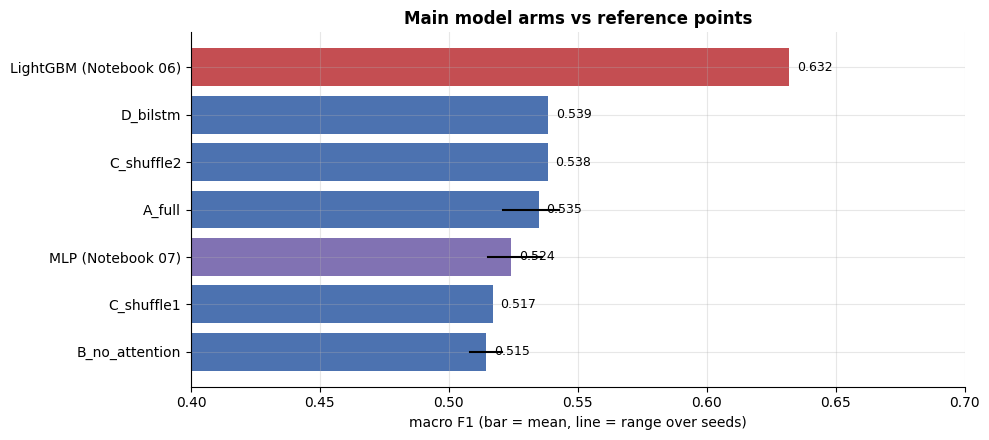

In [14]:
mlp = pd.read_csv(ROOT / 'results/tables/v3/07_mlp_runs.csv')
mlp = mlp[mlp['feature set'] == 'total_and_byte44']
lgbm = pd.read_csv(ROOT / 'results/tables/v3/06_results.csv')
lgbm = lgbm[(lgbm.model == 'lightgbm') & (lgbm['feature set'] == 'total_and_byte44')].iloc[0]

overview = runs.groupby('arm')['macro F1'].agg(['mean', 'std', 'min', 'max', 'count'])
overview.loc['MLP (Notebook 07)'] = [mlp['macro F1'].mean(), mlp['macro F1'].std(), mlp['macro F1'].min(), mlp['macro F1'].max(), len(mlp)]
overview.loc['LightGBM (Notebook 06)'] = [lgbm['macro F1'], 0.0, lgbm['macro F1'], lgbm['macro F1'], 1]
overview = overview.rename(columns={'mean': 'macro F1 mean', 'std': 'std', 'min': 'min', 'max': 'max', 'count': 'runs'}).sort_values('macro F1 mean')
save_table(overview, '08_overview', index=True)
display(overview)

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = {'LightGBM (Notebook 06)': '#C44E52', 'MLP (Notebook 07)': '#8172B3'}
for i, (name, row) in enumerate(overview.iterrows()):
    ax.barh(i, row['macro F1 mean'], color=colors.get(name, '#4C72B0'))
    ax.plot([row['min'], row['max']], [i, i], color='black', lw=1.5)
    ax.text(row['macro F1 mean'] + 0.003, i, f"{row['macro F1 mean']:.3f}", va='center', fontsize=9)
ax.set_yticks(range(len(overview)), overview.index)
ax.set(xlim=(0.4, 0.7), xlabel='macro F1 (bar = mean, line = range over seeds)', title='Main model arms vs reference points')
plt.tight_layout(); save_figure(fig, '08_overview'); plt.show()

### How sure are we? Bootstrap intervals for the key differences

As in Notebook 06: resample the 17,534 `model_selection` rows 1,000 times and look at the middle 95% of the macro F1 differences.
Where both sides have three seeds we compare **seed with seed** (42 with 42, and so on), so every pair shares the same random start.
A difference counts as real only if it holds **for every seed**.

In [15]:
lgbm_pred = pd.Categorical(pd.read_csv(DATA / '06_lightgbm_total_and_byte44_predictions.csv').predicted, categories=CLASSES).codes
mlp_pred = pd.Categorical(pd.read_csv(DATA / '07_mlp_total_and_byte44_seed42_predictions.csv').predicted, categories=CLASSES).codes
pred = {k: p.argmax(1) for k, p in probabilities.items()}
boot_rows = np.random.default_rng(0).integers(0, len(y_eval), size=(1000, len(y_eval)), dtype=np.int32)


def macro(t, p):
    return f1_score(t, p, average='macro', labels=range(10), zero_division=0)


mlp_preds = {seed: pd.Categorical(pd.read_csv(DATA / f'07_mlp_total_and_byte44_seed{seed}_predictions.csv').predicted,
                                   categories=CLASSES).codes for seed in [42, 43, 44]}
comparisons = []
for seed in [42, 43, 44]:
    comparisons += [('A full vs LightGBM', seed, pred[('A_full', seed)], lgbm_pred),
                    ('A full vs MLP', seed, pred[('A_full', seed)], mlp_preds[seed]),
                    ('A full vs B no attention', seed, pred[('A_full', seed)], pred[('B_no_attention', seed)])]
comparisons += [('A full vs C shuffle 1', 42, pred[('A_full', 42)], pred[('C_shuffle1', 42)]),
                ('A full vs C shuffle 2', 42, pred[('A_full', 42)], pred[('C_shuffle2', 42)]),
                ('D BiLSTM vs A full', 42, pred[('D_bilstm', 42)], pred[('A_full', 42)])]
rows = []
for name, seed, first_pred, second_pred in comparisons:
    boot = [macro(y_eval[i], first_pred[i]) - macro(y_eval[i], second_pred[i]) for i in boot_rows]
    low, high = np.percentile(boot, [2.5, 97.5])
    rows.append({'comparison (first minus second)': name, 'seed': seed,
                 'difference': macro(y_eval, first_pred) - macro(y_eval, second_pred), '95% low': low, '95% high': high,
                 'verdict': 'first clearly better' if low > 0 else 'second clearly better' if high < 0 else 'could be chance'})
bootstrap = pd.DataFrame(rows)
save_table(bootstrap, '08_bootstrap')
display(bootstrap)

verdicts = bootstrap.groupby('comparison (first minus second)', sort=False).agg(
    seeds=('seed', 'size'), mean_difference=('difference', 'mean'),
    verdict=('verdict', lambda v: v.iloc[0] if v.nunique() == 1 else 'depends on the seed'))
verdicts = verdicts.rename(columns={'mean_difference': 'mean difference', 'verdict': 'verdict over all seeds'})
save_table(verdicts, '08_verdicts', index=True)
display(verdicts)

,comparison (first minus second),seed,difference,95% low,95% high,verdict
0,A full vs LightGBM,42,-0.0909,-0.1209,-0.0612,second clearly better
1,A full vs MLP,42,0.0051,-0.0157,0.0320,could be chance
2,A full vs B no attention,42,0.0265,0.0064,0.0519,first clearly better
3,A full vs LightGBM,43,-0.0893,-0.1205,-0.0580,second clearly better
4,A full vs MLP,43,0.0274,0.0057,0.0547,first clearly better
5,A full vs B no attention,43,0.0218,0.0120,0.0317,first clearly better
6,A full vs LightGBM,44,-0.1110,-0.1333,-0.0810,second clearly better
7,A full vs MLP,44,-0.0003,-0.0083,0.0081,could be chance
8,A full vs B no attention,44,0.0127,0.0043,0.0213,first clearly better
9,A full vs C shuffle 1,42,0.0240,0.0037,0.0521,first clearly better


,seeds,mean difference,verdict over all seeds
comparison (first minus second),,,
A full vs LightGBM,3,-0.0971,second clearly better
A full vs MLP,3,0.0107,depends on the seed
A full vs B no attention,3,0.0203,first clearly better
A full vs C shuffle 1,1,0.0240,first clearly better
A full vs C shuffle 2,1,0.0028,could be chance
D BiLSTM vs A full,1,-0.0025,could be chance


**What we see:**

| Comparison | Result | Verdict |
|---|---|---|
| **A (full) vs LightGBM** | 0.535 vs 0.632, about -0.097 | LightGBM **clearly better for every seed** |
| **A (full) vs MLP** | 0.535 vs 0.524, about +0.011 | **Depends on the seed**: clear for seed 43, chance for seeds 42 and 44 |
| **A (full) vs B (no attention)** | 0.535 vs 0.515, about +0.020 | Attention **clearly helps for every seed** |
| **A vs C (shuffled order)** | shuffle 1: -0.024 (clear), shuffle 2: -0.003 (chance) | **Mixed**: the topic order is not reliably used |
| **D (+ BiLSTM) vs A** | -0.003 | **No gain** from the BiLSTM |

In plain words: inside the neural family, **attention is the one part that clearly earns its place**. But the whole network is only about as good
as a plain MLP, and well below LightGBM.

## 13. Class by class: the full model vs LightGBM

,rows,Conv1D+attention correct,LightGBM correct,MLP correct,Conv1D+attention F1,LightGBM F1
Analysis,200,28,30,21,0.2240,0.2372
Backdoor,175,20,26,15,0.1980,0.2332
DoS,1226,33,86,271,0.0515,0.1269
Exploits,3340,3185,3192,2942,0.7417,0.7539
Fuzzers,1818,1262,1391,1304,0.7011,0.7580
Generic,4000,3908,3923,3911,0.9877,0.9899
Normal,5600,5071,5127,4961,0.9168,0.9303
Reconnaissance,1049,792,779,763,0.8195,0.8243
Shellcode,113,71,88,71,0.6368,0.7458
Worms,13,1,9,0,0.1333,0.7200


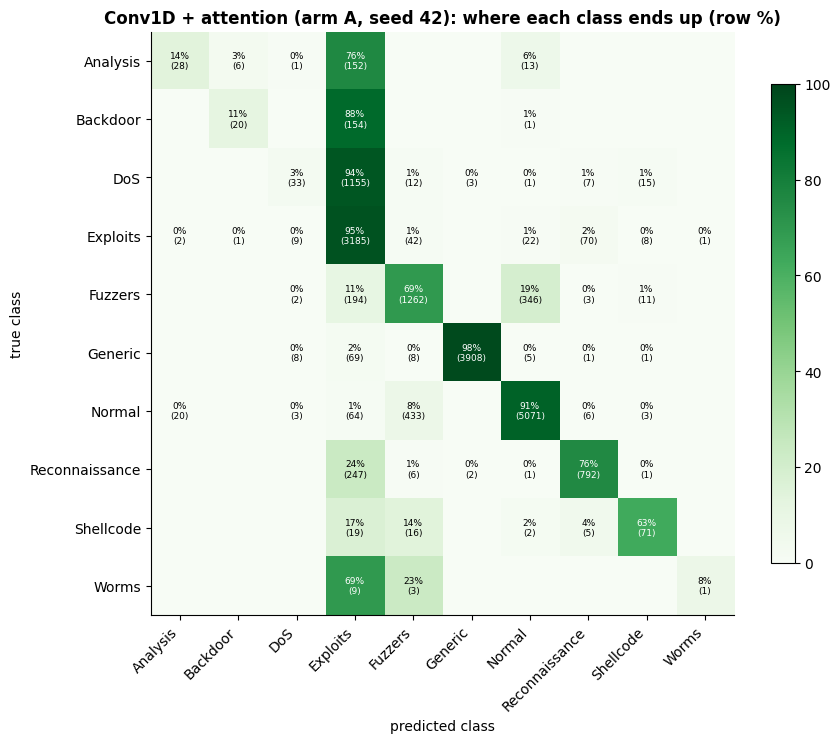

In [16]:
full_pred = pred[('A_full', 42)]
by_class = pd.DataFrame({'rows': np.bincount(y_eval, minlength=10),
                         'Conv1D+attention correct': [int(((y_eval == k) & (full_pred == k)).sum()) for k in range(10)],
                         'LightGBM correct': [int(((y_eval == k) & (lgbm_pred == k)).sum()) for k in range(10)],
                         'MLP correct': [int(((y_eval == k) & (mlp_pred == k)).sum()) for k in range(10)]}, index=CLASSES)
by_class['Conv1D+attention F1'] = f1_score(y_eval, full_pred, average=None, labels=range(10), zero_division=0)
by_class['LightGBM F1'] = f1_score(y_eval, lgbm_pred, average=None, labels=range(10), zero_division=0)
save_table(by_class, '08_by_class', index=True)
display(by_class)

cm = confusion_matrix(y_eval, full_pred, labels=range(10))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm_pct, cmap='Greens', vmin=0, vmax=100)
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right'); ax.set_yticks(range(10), CLASSES); ax.grid(False)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, f'{cm_pct[i, j]:.0f}%\n({cm[i, j]})', ha='center', va='center', fontsize=6.5,
                    color='white' if cm_pct[i, j] > 60 else 'black')
ax.set(xlabel='predicted class', ylabel='true class', title='Conv1D + attention (arm A, seed 42): where each class ends up (row %)')
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); save_figure(fig, '08_full_model_confusion'); plt.show()

**What we see:**

- The network is close to LightGBM on the big classes (Generic, Exploits, Normal, Reconnaissance), and slightly better on Reconnaissance (792 vs 779 correct).
- It loses most on the **small classes**: **Worms 1 of 13** (LightGBM 9), Shellcode 71 vs 88, and DoS 33 vs 86.
  Macro F1 gives every class equal weight, so these small classes explain most of the gap.
- Analysis, Backdoor and DoS still go mostly to Exploits, the label-conflict problem from Notebook 02 that no model has solved.

## 14. What does the attention look at?

For 3,000 `model_selection` flows we record the attention weights of the full model and average them.
"Attention received" says how much the other positions looked at each feature. This describes **what the model uses**;
it is not proof of what causes an attack.

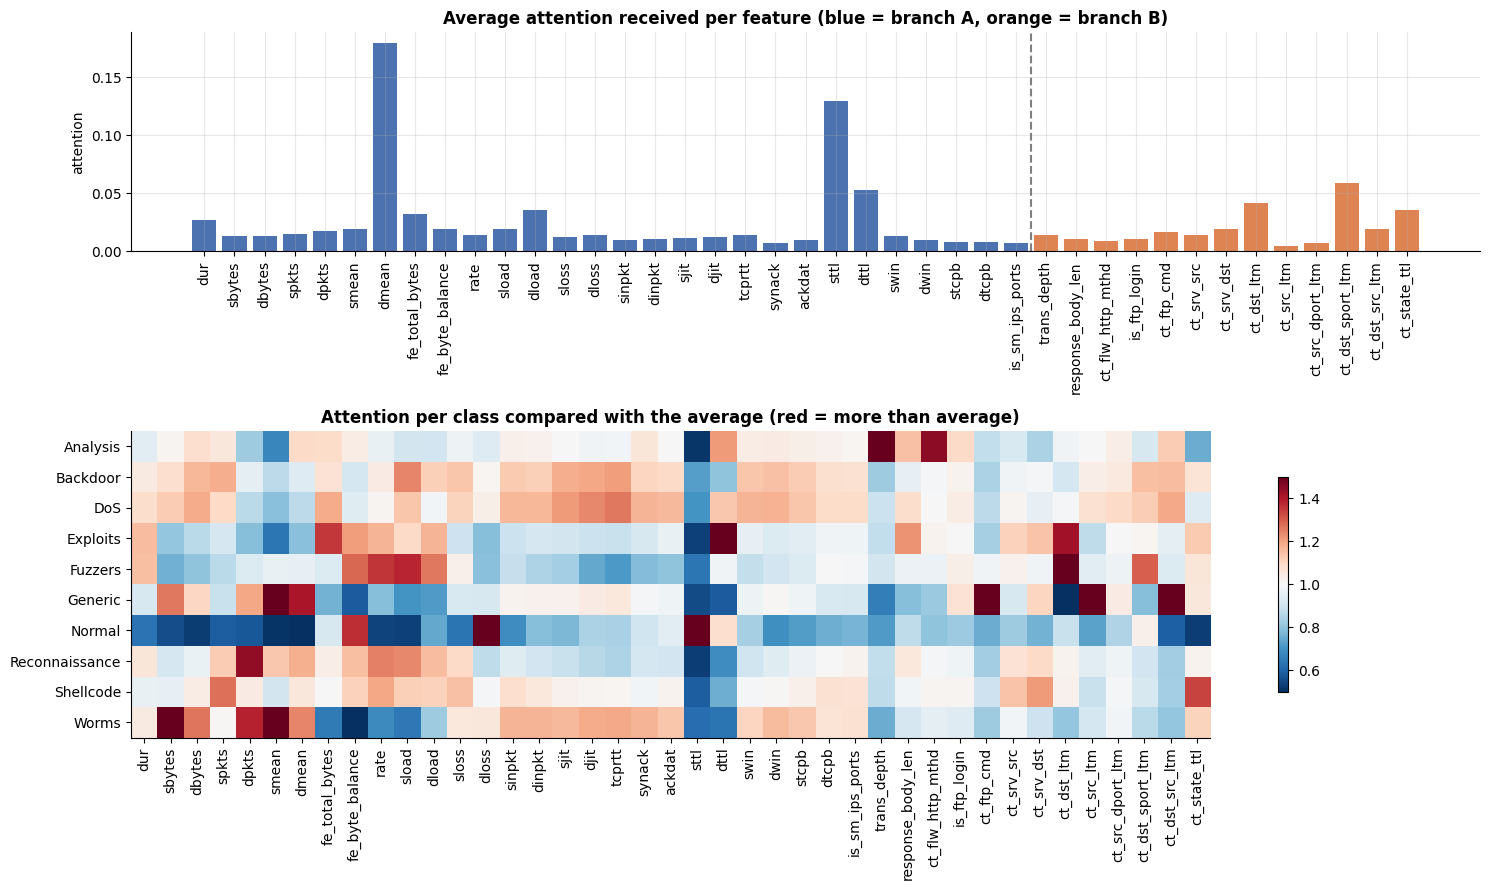

,dmean,sttl,ct_dst_sport_ltm,dttl,ct_dst_ltm,dload,ct_state_ttl,fe_total_bytes
attention received,0.1799,0.1297,0.0586,0.0528,0.0421,0.0358,0.0354,0.0319


In [17]:
model = networks[('A_full', 42)]
model.eval()
sample = np.random.default_rng(1).choice(len(y_eval), 3000, replace=False)
with torch.no_grad():
    _, weights = model(data['model_selection'][0][sample], data['model_selection'][1][sample], return_attention=True)
received = weights.mean(dim=(0, 1)).numpy()                      # average over flows and query positions
per_class = pd.DataFrame({CLASSES[k]: weights[torch.from_numpy(y_eval[sample] == k)].mean(dim=(0, 1)).numpy()
                          for k in range(10) if (y_eval[sample] == k).any()}, index=names).T

fig, axes = plt.subplots(2, 1, figsize=(15, 9), gridspec_kw={'height_ratios': [1, 1.4]})
axes[0].bar(range(41), received, color=['#4C72B0'] * 28 + ['#DD8452'] * 13)
axes[0].set_xticks(range(41), names, rotation=90); axes[0].axvline(27.5, color='grey', ls='--')
axes[0].set(title='Average attention received per feature (blue = branch A, orange = branch B)', ylabel='attention')
im = axes[1].imshow(per_class / per_class.mean(axis=0), cmap='RdBu_r', vmin=0.5, vmax=1.5, aspect='auto')
axes[1].set_xticks(range(41), names, rotation=90); axes[1].set_yticks(range(len(per_class)), per_class.index); axes[1].grid(False)
axes[1].set_title('Attention per class compared with the average (red = more than average)')
fig.colorbar(im, ax=axes[1], shrink=0.7)
plt.tight_layout(); save_figure(fig, '08_attention'); plt.show()
display(pd.Series(received, index=names).sort_values(ascending=False).head(8).rename('attention received').to_frame().T)

**What we see:** Attention concentrates on a few features: **`dmean`** (average reply packet size) and **`sttl`** (TTL) receive the most,
followed by some "recent flows" counters. `sttl` was also LightGBM's top feature (Notebook 06), and `dmean` is closely tied to "did anything come back"
(Notebook 04). The two very different models rely on similar signals, including the testbed-specific TTL.

## 15. What does each model cost?

A detector also has to be practical. We compare model size, training time and prediction time.

- **Prediction time:** all models predict the same 17,534 `model_selection` rows here, one after another (best of 3 timings).
- **Training time of the networks:** the recorded wall-clock times are not comparable, because some arms were trained while other jobs shared
  the CPU. So we **measure one training epoch of each network here, under the same conditions**, and multiply by the number of epochs it needed.
- LightGBM and MLP training times come from Notebooks 06 and 07 and are rough (machine load varied).

In [18]:
import joblib


def best_time(predict, repeats=3):
    times = []
    for _ in range(repeats):
        start = time.perf_counter(); predict(); times.append(time.perf_counter() - start)
    return min(times)


lgbm_model = joblib.load(MODELS / '06_lightgbm_total_and_byte44.joblib')
lgbm_x = sparse.load_npz(DATA / '05_total_and_byte44_tree_model_selection.npz')
mlp_model = joblib.load(MODELS / '07_mlp_total_and_byte44_seed42.joblib')
mlp_x = sparse.load_npz(DATA / '05_total_and_byte44_scaled_model_selection.npz')
board_06 = pd.read_csv(ROOT / 'results/tables/v3/leaderboard_06.csv').set_index(['model', 'feature set'])
board_07 = pd.read_csv(ROOT / 'results/tables/v3/leaderboard_07.csv').set_index(['model', 'feature set'])
n_leaves = sum(t['num_leaves'] for t in lgbm_model.booster_.dump_model()['tree_info'])

cost = [{'model': 'LightGBM', 'size': f'{n_leaves:,} tree leaves',
         'train minutes': board_06.loc[('LightGBM', 'total_and_byte44'), 'train minutes per run'],
         'predict seconds': best_time(lambda: lgbm_model.predict_proba(lgbm_x))},
        {'model': 'MLP', 'size': f"{board_07.loc[('MLP (128/64)', 'total_and_byte44'), 'parameters']:,.0f} weights",
         'train minutes': board_07.loc[('MLP (128/64)', 'total_and_byte44'), 'train minutes per run'],
         'predict seconds': best_time(lambda: mlp_model.predict_proba(mlp_x))}]
def seconds_per_epoch(arm, batch_size=512):
    """Time one full training epoch of a fresh network (same data, same batch size, same threads)."""
    torch.manual_seed(0)
    net = ConvAttentionNet(use_attention=ARMS[arm]['use_attention'], use_bilstm=ARMS[arm]['use_bilstm'])
    optimizer, loss_fn = torch.optim.Adam(net.parameters(), lr=0.001), nn.CrossEntropyLoss()
    x, c, t = data['train'][0][learn_rows], data['train'][1][learn_rows], data['train'][2][learn_rows]
    net.train(); start = time.perf_counter()
    for i in range(0, len(t), batch_size):
        optimizer.zero_grad(); loss_fn(net(x[i:i + batch_size], c[i:i + batch_size]), t[i:i + batch_size]).backward(); optimizer.step()
    return time.perf_counter() - start


epoch_seconds = {}
for arm in ['A_full', 'B_no_attention', 'D_bilstm']:
    net = networks[(arm, 42)]
    epoch_seconds[arm] = seconds_per_epoch(arm)
    mean_epochs = np.mean([len(histories[(arm, s)]) for s in ARMS[arm]['seeds']])
    cost.append({'model': f'Conv1D arm {arm}', 'size': f'{sum(p.numel() for p in net.parameters()):,} weights',
                 'seconds per epoch': epoch_seconds[arm], 'epochs used (mean)': mean_epochs,
                 'train minutes': epoch_seconds[arm] * mean_epochs / 60,
                 'predict seconds': best_time(lambda: predict_proba(net, data['model_selection'][0], data['model_selection'][1]))})
epoch_seconds['C_shuffle1'] = epoch_seconds['C_shuffle2'] = epoch_seconds['A_full']   # same network as A, only the column order differs
cost = pd.DataFrame(cost)
cost['predict ms per 1,000 flows'] = cost['predict seconds'] / len(y_eval) * 1000 * 1000
save_table(cost, '08_cost')
display(cost.drop(columns='predict seconds'))

,model,size,train minutes,seconds per epoch,epochs used (mean),"predict ms per 1,000 flows"
0,LightGBM,"37,200 tree leaves",0.2367,NaN,NaN,34.5928
1,MLP,"33,994 weights",0.4620,NaN,NaN,1.6100
2,Conv1D arm A_full,"46,002 weights",6.8600,9.6469,42.6667,23.5277
3,Conv1D arm B_no_attention,"29,362 weights",2.8736,2.5606,67.3333,4.9789
4,Conv1D arm D_bilstm,"71,090 weights",8.6736,14.4561,36.0000,37.5213


In [19]:
# Interpretation computed from this run's measurements (timings change with hardware, PyTorch build and machine load).
by = cost.set_index('model')
conv_train = by.loc[[m for m in by.index if m.startswith('Conv1D')], 'train minutes']
print(f"Measured on: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only'} available, networks run on CPU; "
      f"PyTorch {torch.__version__}, {torch.get_num_threads()} threads")
print(f"- LightGBM training: {by.loc['LightGBM', 'train minutes']:.1f} min vs networks {conv_train.min():.1f}-{conv_train.max():.1f} min "
      f"-> LightGBM is {conv_train.min() / by.loc['LightGBM', 'train minutes']:.0f}x or more cheaper to train")
print(f"- Seconds per epoch: with attention {by.loc['Conv1D arm A_full', 'seconds per epoch']:.1f} s, without {by.loc['Conv1D arm B_no_attention', 'seconds per epoch']:.1f} s, "
      f"with BiLSTM {by.loc['Conv1D arm D_bilstm', 'seconds per epoch']:.1f} s; epochs needed: {by.loc['Conv1D arm A_full', 'epochs used (mean)']:.0f} vs "
      f"{by.loc['Conv1D arm B_no_attention', 'epochs used (mean)']:.0f} vs {by.loc['Conv1D arm D_bilstm', 'epochs used (mean)']:.0f}")
print(f"- Slowest prediction: {cost['predict ms per 1,000 flows'].max():.0f} ms per 1,000 flows -> every model is fast enough for offline analysis")

Measured on: NVIDIA GeForce RTX 4060 Laptop GPU available, networks run on CPU; PyTorch 2.14.0+cu130, 8 threads
- LightGBM training: 0.2 min vs networks 2.9-8.7 min -> LightGBM is 12x or more cheaper to train
- Seconds per epoch: with attention 9.6 s, without 2.6 s, with BiLSTM 14.5 s; epochs needed: 43 vs 67 vs 36
- Slowest prediction: 38 ms per 1,000 flows -> every model is fast enough for offline analysis


**What we see:** the printout above gives this run's exact numbers. Absolute timings change between machines, PyTorch builds and runs
(they are measured, not fixed properties of the models), so only the large differences are meaningful:

- **LightGBM is by far the cheapest model to train**, and it is also the most accurate.
- Attention makes each epoch more expensive but the network needs fewer epochs; the BiLSTM makes every epoch slower still, with no gain in accuracy.
- Every model predicts fast enough for offline analysis of flow records.

## 16. All models in one table

Every model trained in Notebooks 06, 07 and 08, scored the same way on the same `model_selection` rows. This is the table to report.
For models trained with several seeds the score is the mean, and "std" shows how much it moves between seeds.

,notebook,model,feature set,runs,macro F1 mean,macro F1 std,accuracy,attack recall,false-positive rate,attack avg precision,Worms correct (of 13)
0,06,LightGBM,total_and_byte44,1,0.6320,NaN,0.8356,0.9753,0.0845,0.9967,9.0000
1,06,LightGBM,original42,1,0.6307,NaN,0.8366,0.9760,0.0846,0.9968,8.0000
2,06,Decision tree,original42,3,0.6117,0.0019,0.8153,0.9644,0.0886,0.9740,6.3333
3,06,Decision tree,total_and_byte44,3,0.6107,0.0058,0.8139,0.9624,0.0843,0.9733,7.0000
4,08,Conv1D + attention + BiLSTM (D),total_and_byte44,1,0.5385,NaN,0.8209,0.9656,0.0893,0.9959,1.0000
5,08,"Conv1D + attention, shuffled order 2 (C)",total_and_byte44,1,0.5383,NaN,0.8222,0.9688,0.0929,0.9959,1.0000
6,08,Conv1D + attention (A),total_and_byte44,3,0.5349,0.0121,0.8206,0.9688,0.0961,0.9959,0.6667
7,07,MLP (128/64),total_and_byte44,3,0.5241,0.0107,0.8133,0.9756,0.1168,0.9956,0.0000
8,07,MLP (128/64),original42,3,0.5198,0.0069,0.8155,0.9714,0.1046,0.9957,0.0000
9,08,"Conv1D + attention, shuffled order 1 (C)",total_and_byte44,1,0.5170,NaN,0.8214,0.9708,0.0989,0.9959,0.0000


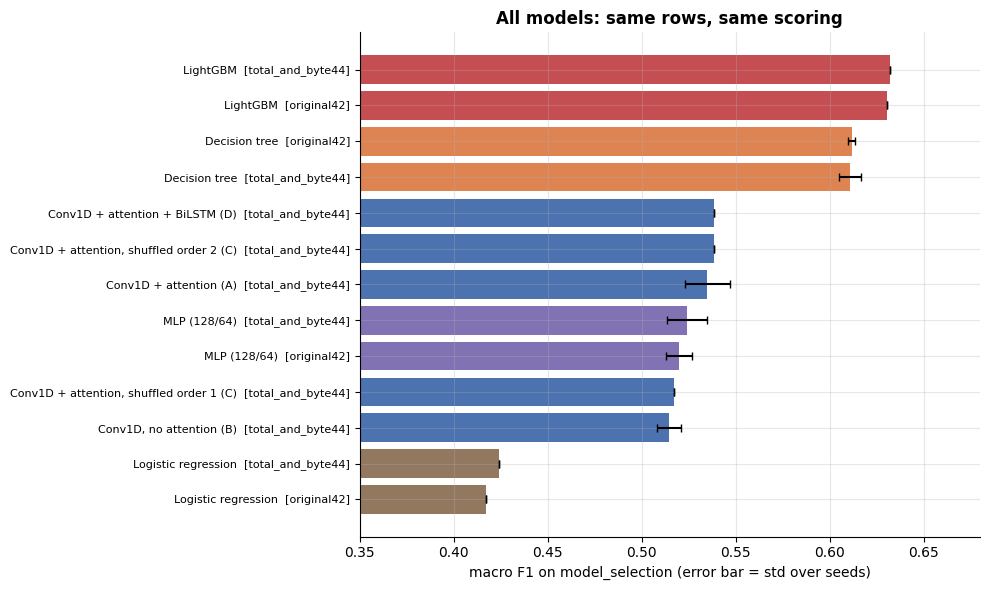

In [20]:
arm_names = {'A_full': 'Conv1D + attention (A)', 'B_no_attention': 'Conv1D, no attention (B)',
             'C_shuffle1': 'Conv1D + attention, shuffled order 1 (C)', 'C_shuffle2': 'Conv1D + attention, shuffled order 2 (C)',
             'D_bilstm': 'Conv1D + attention + BiLSTM (D)'}
board_rows = []
for arm, label in arm_names.items():
    part = runs[runs.arm == arm]
    board_rows.append({'model': label, 'feature set': 'total_and_byte44', 'runs': len(part),
                       'macro F1 mean': part['macro F1'].mean(), 'macro F1 std': part['macro F1'].std() if len(part) > 1 else np.nan,
                       'accuracy': part['accuracy'].mean(), 'attack recall': part['attack recall'].mean(),
                       'false-positive rate': part['false-positive rate'].mean(), 'attack avg precision': part['attack avg precision'].mean(),
                       'Worms correct (of 13)': part['Worms correct (of 13)'].mean(),
                       'parameters': sum(p.numel() for p in networks[(arm, 42)].parameters()),
                       'train minutes per run': epoch_seconds[arm] * np.mean([len(histories[(arm, s)]) for s in ARMS[arm]['seeds']]) / 60})
write_leaderboard('08', board_rows)
board = read_leaderboard(upto='08')
save_table(board, 'all_models_results')
display(board.drop(columns=['parameters', 'train minutes per run']))

fig, ax = plt.subplots(figsize=(10, 6))
shown = board.iloc[::-1]
family = shown.model.str.split(' ').str[0].str.rstrip(',')
palette = {'LightGBM': '#C44E52', 'Decision': '#DD8452', 'Logistic': '#937860', 'MLP': '#8172B3', 'Conv1D': '#4C72B0'}
ax.barh(range(len(shown)), shown['macro F1 mean'], xerr=shown['macro F1 std'].fillna(0), color=[palette.get(f, '#999999') for f in family], capsize=3)
ax.set_yticks(range(len(shown)), shown.model + '  [' + shown['feature set'] + ']', fontsize=8)
ax.set(xlabel='macro F1 on model_selection (error bar = std over seeds)', title='All models: same rows, same scoring', xlim=(0.35, 0.68))
plt.tight_layout(); save_figure(fig, '08_all_models'); plt.show()

**What we see:** the ranking is the same whichever way we look at it: **LightGBM (0.63) > decision tree (0.61) > the neural networks
(0.51-0.54) > logistic regression (0.42)**. Within the neural networks, the arms with attention sit at the top and the no-attention arm at the
bottom. All models catch about 96-98% of attacks; they differ mainly in the attack *types* and in Worms (LightGBM 9 of 13, every network 0-1).

## 17. Save

In [21]:
for (arm, seed), proba in probabilities.items():
    out = targets['model_selection'][['row_position', 'id', 'attack_cat']].copy()
    out['predicted'] = np.asarray(CLASSES)[proba.argmax(1)]
    out['attack_score'] = 1 - proba[:, NORMAL]
    for k, c in enumerate(CLASSES):
        out[f'p_{c}'] = proba[:, k]
    out.to_csv(DATA / f'08_{arm}_seed{seed}_predictions.csv', index=False)
pd.concat({f'{a} seed {s}': h for (a, s), h in histories.items()}).to_csv(DATA / '08_training_histories.csv')
save_json({'architecture': 'two Conv1D branches (28 + 13 ordered number features) -> fusion + position -> 4-head attention -> mean pool '
                           '+ text embeddings -> dense 128 -> 10 classes',
           'branch_a': BRANCH_A, 'branch_b': BRANCH_B, 'shuffles': {k: v.tolist() for k, v in SHUFFLES.items()},
           'training': 'Adam 0.001, batch 512, dropout 0.2, max 100 epochs, early stopping patience 5 on 10% grouped stopping rows of train',
           'inputs': 'scaled total_and_byte44 (Notebook 05)', 'scope': 'tabular adaptation; no DNS, no time windows'},
          MODELS / '08_settings.json')
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print(f'Saved {len(probabilities)} runs: checkpoints in {CHECKPOINTS.relative_to(ROOT)}, predictions in data/processed/v3/. '
      'Calibration rows and the test file were not used.')

Saved 9 runs: checkpoints in models\v3\08_checkpoints, predictions in data/processed/v3/. Calibration rows and the test file were not used.


## Summary

### What we learned

| Question | Answer |
|---|---|
| Does Conv1D + attention beat LightGBM? | **No.** Mean macro F1 **0.535 ± 0.012** vs **0.632**, clearly worse for every seed |
| Does it beat the plain MLP? | **Not reliably** (0.535 vs 0.524): clear for one seed out of three |
| Does attention help? | **Yes.** With attention 0.535, without 0.515; clearly better for all three seeds, with every arm trained to early stopping |
| Does the feature order matter? | **Unclear**: one shuffle hurt, the other did not |
| Does the paper's BiLSTM help here? | **No** gain on single flow rows, and it is slower |
| Where is the gap to LightGBM? | Mostly the small classes: Worms (1 vs 9 of 13), Shellcode and DoS |
| What does attention look at? | Mostly `dmean` and `sttl`, signals LightGBM also relies on |

### What this means for the project

On **one-row-per-flow data**, the paper-style network is a **reasonable neural model but not the best detector**. Its attention block clearly
helps compared with plain convolution, but a well-configured tree ensemble is more accurate, cheaper to train and fully reproducible.
The paper's main ingredients, DNS-query features and time windows, depend on data this dataset does not contain, so we could not test them here.
This is itself a useful, honest result: **architecture choices from a flow+DNS setting do not automatically transfer to flow-only data.**

### What is still uncertain

- Wider tuning of the network (size, learning rate) was not done; it might narrow the gap a little, but a gap of about 0.10 is large.
- The small classes have very few rows (Worms 13), so their results swing a lot.
- All scores are on `model_selection`, not the official test file.

### Possible next steps

1. **Help the rare classes:** class weighting or balanced sampling, tested on the network **and** on a matched weighted LightGBM, so the comparison stays fair.
2. **Calibrate confidence** of the chosen model on the reserved `calibration` rows.
3. **Explain predictions** (SHAP) for the chosen model.
4. **Final evaluation** once on the official test file, reporting "seen in training" vs "new" rows (Notebook 02).